# Gezichtsherkenning: is dit dezelfde persoon?

**Topic 4 — PXL**

---

We bouwen een systeem dat twee foto's krijgt en zegt of daar dezelfde persoon op staat.
Zonder zelf een gezichtsmodel te trainen — dat zou miljoenen foto's en dagen rekentijd kosten.

| Idee | Wat het betekent | Waar je het ziet |
|---|---|---|
| **Transfer learning** | Een netwerk dat al iets geleerd heeft hergebruiken voor jouw probleem | §3: FaceNet zet elk gezicht om in 512 getallen |
| **Contrastive learning** | Niet leren "wat is dit?" maar "welke twee horen bij elkaar?" | §4: zo is FaceNet zelf getraind |

## 0. Setup

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"      # TensorFlow wat stiller maken

# MTCNN laadt zijn gewichten uit .lz4-bestanden. Door een bug in die bibliotheek
# wordt zo'n bestand bij het sluiten nog "geflusht" alsof erin geschreven is,
# terwijl het alleen gelezen werd. Dat geeft drie rode maar onschuldige
# foutblokken. We laten flush() alleen nog iets doen bij schrijven.
import lz4.frame
_lz4_flush = lz4.frame.LZ4FrameFile.flush
lz4.frame.LZ4FrameFile.flush = lambda self: _lz4_flush(self) if self.writable() else None

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

import keras
from keras import layers, ops

from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score, roc_curve

# De twee voorgetrainde modellen die we lenen.
from mtcnn import MTCNN                    # gezichten vinden
from keras_facenet import FaceNet          # gezichten omzetten in getallen

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

print("keras     ", keras.__version__, "| backend:", keras.backend.backend())
import tensorflow as tf; print("tensorflow", tf.__version__)

keras      3.15.1 | backend: tensorflow
tensorflow 2.21.0


## 1. De foto's

We gebruiken **LFW** (Labeled Faces in the Wild): foto's van bekende personen, zoals ze op het
internet gevonden zijn. Geen studiofoto's dus — wisselend licht, verschillende hoeken,
brillen, microfoons voor het gezicht. Precies wat je wil om te testen of iets robuust is.

`haal_data.py` heeft er 16 personen uit gehaald met elk 40 foto's, en die als losse JPEG's
neergezet. De mappenstructuur *is* de dataset:

```
data/gezichten/
├── George_W_Bush/0001.jpg ...
├── Colin_Powell/0001.jpg ...
└── ...
```

Wil je later je eigen gezicht toevoegen, dan maak je gewoon zo'n map bij. Meer is het niet.

In [2]:
MAP = Path("data/gezichten")
if not MAP.exists():
    raise FileNotFoundError(
        "Foto's niet gevonden. Draai eerst eenmalig:  .venv/bin/python haal_data.py")

paden  = sorted(MAP.rglob("*.jpg"))
namen  = np.array([p.parent.name.replace("_", " ") for p in paden])
personen = sorted(set(namen))

print(f"{len(paden)} foto's van {len(personen)} personen")
for p in personen:
    print(f"   {p:28s} {(namen == p).sum():3d} foto's")

640 foto's van 16 personen
   Ariel Sharon                  40 foto's
   Colin Powell                  40 foto's
   Donald Rumsfeld               40 foto's
   George W Bush                 40 foto's
   Gerhard Schroeder             40 foto's
   Gloria Macapagal Arroyo       40 foto's
   Hugo Chavez                   40 foto's
   Jacques Chirac                40 foto's
   Jean Chretien                 40 foto's
   Jennifer Capriati             40 foto's
   John Ashcroft                 40 foto's
   Junichiro Koizumi             40 foto's
   Luiz Inacio Lula da Silva     40 foto's
   Serena Williams               40 foto's
   Tony Blair                    40 foto's
   Vladimir Putin                40 foto's


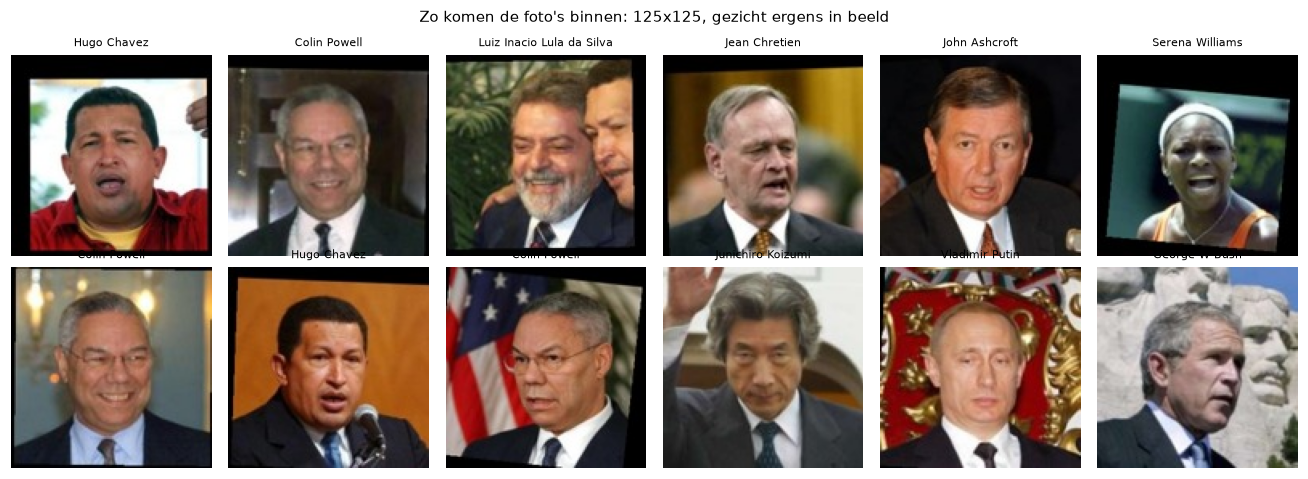

In [3]:
# Een willekeurige greep, zodat je ziet waar we mee werken.
fig, assen = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, k in zip(assen.ravel(), rng.choice(len(paden), 12, replace=False)):
    ax.imshow(Image.open(paden[k]))
    ax.set_title(namen[k], fontsize=7)
    ax.axis("off")
fig.suptitle("Zo komen de foto's binnen: 125x125, gezicht ergens in beeld", fontsize=10)
plt.tight_layout()
plt.show()

---

## 2. Gezichten vinden met MTCNN

Voor je iets over een gezicht kunt zeggen, moet je het eerst **vinden**. Dat is een apart
probleem, en we lossen het op met **MTCNN** (Multi-task Cascaded Convolutional Networks).

MTCNN kijkt in drie rondes naar de foto. Ronde één zet grof duizenden kandidaat-kadertjes uit,
ronde twee gooit de onzin weg, ronde drie verfijnt wat overblijft en zoekt meteen vijf
**landmarks**: twee ogen, de neus en twee mondhoeken.

Dat we die landmarks krijgen is geen extraatje — daarmee kun je het gezicht rechtzetten
voordat je het doorstuurt, en dat maakt de rest een stuk betrouwbaarder.

In [4]:
detector = MTCNN()

# Eén foto, om te zien wat eruit komt.
voorbeeld = np.array(Image.open(paden[0]).convert("RGB"))
gevonden  = detector.detect_faces(voorbeeld)

print(f"gevonden gezichten: {len(gevonden)}")
for g in gevonden:
    print(f"  box (x, y, breedte, hoogte): {g['box']}")
    print(f"  zekerheid                  : {g['confidence']:.4f}")
    print(f"  landmarks                  : {list(g['keypoints'])}")

gevonden gezichten: 2
  box (x, y, breedte, hoogte): [36, 29, 47, 68]
  zekerheid                  : 0.9995
  landmarks                  : ['nose', 'mouth_right', 'right_eye', 'left_eye', 'mouth_left']
  box (x, y, breedte, hoogte): [83, 0, 31, 25]
  zekerheid                  : 0.9525
  landmarks                  : ['nose', 'mouth_right', 'right_eye', 'left_eye', 'mouth_left']


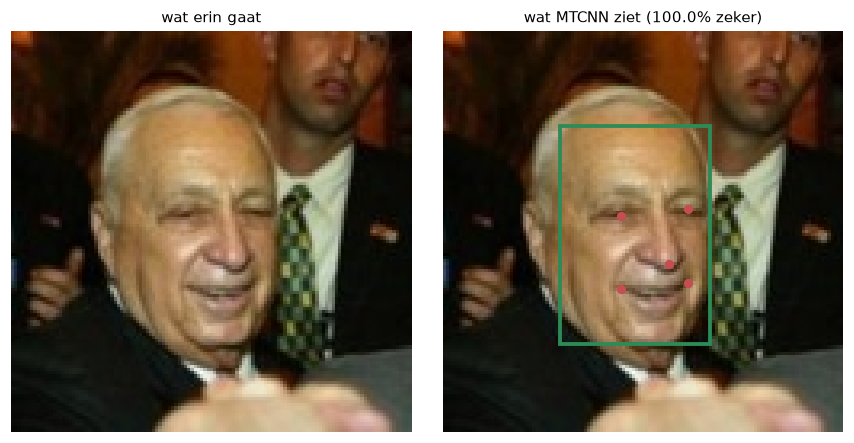

In [5]:
# Hetzelfde, maar dan zichtbaar.
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 4))

a.imshow(voorbeeld); a.set_title("wat erin gaat", fontsize=10); a.axis("off")

b.imshow(voorbeeld)
x, y, w, h = gevonden[0]["box"]
b.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="#2E8B57", lw=2.5))
for naam_punt, (px, py) in gevonden[0]["keypoints"].items():
    b.plot(px, py, "o", ms=5, color="#C44E52")
b.set_title(f"wat MTCNN ziet ({gevonden[0]['confidence']:.1%} zeker)", fontsize=10)
b.axis("off")

plt.tight_layout()
plt.show()

### Alle foto's door de detector

Nu draaien we dit over de hele verzameling. Voor elk gezicht knippen we de bounding box uit en
schalen we naar 160×160 — dat is de maat die FaceNet verwacht.

> **Let op de teller onderaan.** Een detector die gezichten mist, is een detector die
> stilletjes rijen uit je dataset laat vallen. Dat wil je weten, niet vermoeden.

In [6]:
def knip_gezicht(pad, marge=0.15):
    # Geeft een 160x160 uitsnede terug, of None als er geen gezicht gevonden wordt.
    foto = np.array(Image.open(pad).convert("RGB"))
    kandidaten = detector.detect_faces(foto)
    if not kandidaten:
        return None

    # Meerdere gezichten? Neem het meest zekere.
    beste = max(kandidaten, key=lambda d: d["confidence"])
    x, y, w, h = beste["box"]

    # Een beetje marge eromheen: het kaartje zit vaak strak om de neus en kin.
    dx, dy = int(w * marge), int(h * marge)
    x, y = max(0, x - dx), max(0, y - dy)
    uitsnede = foto[y:y + h + 2 * dy, x:x + w + 2 * dx]
    if uitsnede.size == 0:
        return None

    return np.array(Image.fromarray(uitsnede).resize((160, 160)))


# We houden ook bij WELKE paden gelukt zijn, zodat foto's, uitsnedes en labels
# gegarandeerd op dezelfde index blijven staan. Mislukt er later toch een detectie,
# dan schuift er niets stiekem door elkaar.
gezichten, labels, paden_ok, mislukt = [], [], [], []
for pad, naam in zip(paden, namen):
    uitsnede = knip_gezicht(pad)
    if uitsnede is None:
        mislukt.append(pad)
        continue
    gezichten.append(uitsnede)
    labels.append(naam)
    paden_ok.append(pad)

gezichten = np.array(gezichten)
labels    = np.array(labels)
paden_ok  = np.array(paden_ok)

print(f"gezichten uitgeknipt : {len(gezichten)}")
print(f"geen gezicht gevonden: {len(mislukt)}")
print(f"vorm                 : {gezichten.shape}")

gezichten uitgeknipt : 640
geen gezicht gevonden: 0
vorm                 : (640, 160, 160, 3)


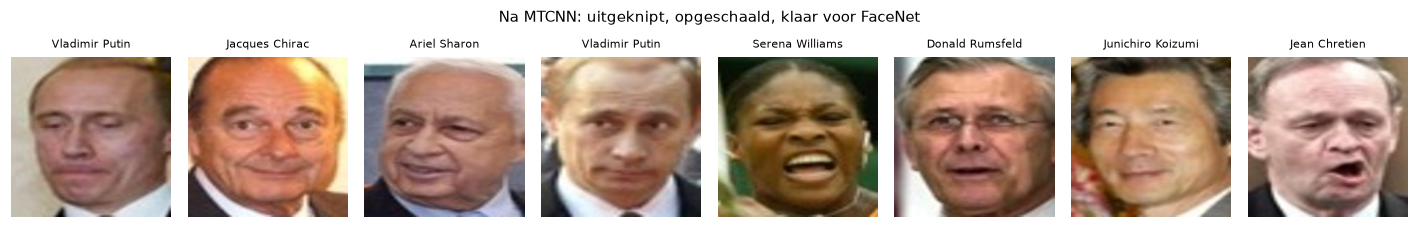

In [7]:
fig, assen = plt.subplots(1, 8, figsize=(13, 2.1))
for ax, k in zip(assen, np.random.default_rng(1).choice(len(gezichten), 8, replace=False)):
    ax.imshow(gezichten[k]); ax.set_title(labels[k], fontsize=7); ax.axis("off")
fig.suptitle("Na MTCNN: uitgeknipt, opgeschaald, klaar voor FaceNet", fontsize=10)
plt.tight_layout()
plt.show()

---

## 3. Van gezicht naar embedding

Nu het stuk waar transfer learning gebeurt.

**FaceNet** is een netwerk dat getraind is op miljoenen gezichten van duizenden mensen. Het is
niet getraind om namen te voorspellen — het is getraind om van elk gezicht een **lijstje van 512
getallen** te maken met één eigenschap:

> Twee foto's van **dezelfde** persoon krijgen lijstjes die dicht bij elkaar liggen.
> Twee foto's van **verschillende** personen krijgen lijstjes die ver uit elkaar liggen.

Zo'n lijstje heet een **embedding**. Je kunt het zien als een vingerafdruk: geen plaatje meer,
maar een positie in een ruimte van 512 dimensies, waar "dichtbij" letterlijk "lijkt op" betekent.

En dat is precies wat wij kunnen lenen. Wij hoeven FaceNet niets te leren — we gebruiken alleen
zijn uitvoer.

In [8]:
embedder = FaceNet()

# Alle uitsnedes in één keer door het netwerk.
embeddings = embedder.embeddings(gezichten)

print(f"vorm: {embeddings.shape}   ({embeddings.shape[0]} gezichten x {embeddings.shape[1]} getallen)")
print(f"lengte van elke vector: {np.linalg.norm(embeddings, axis=1)[:5].round(3)}")
print()
print("Alle vectoren hebben lengte 1.")
print()
print("Dat is geen toeval maar een ontwerpkeuze van FaceNet. Doordat de lengte")
print("van elke vector vastligt, blijft er nog maar één ding over waarin twee")
print("gezichten van elkaar kunnen verschillen: de RICHTING waarin hun vector")
print("wijst. Alle afstanden liggen daardoor op dezelfde schaal en zijn dus")
print("onderling vergelijkbaar.")
print()
print("Zo ziet één gezicht eruit als getallen (eerste 8 van de 512):")
print(embeddings[0][:8].round(4))
print()
print("Die getallen zijn klein, en lengte 1 lijkt dan vreemd. Maar de lengte")
print("is niet de grootte van één getal: het is de wortel van de som van alle")
print("512 kwadraten. Lagen ze allemaal even ver van nul, dan was elk getal")
print(f"1/wortel(512) = {1/np.sqrt(512):.4f}. Even narekenen:")
print(f"  som van alle kwadraten : {(embeddings[0] ** 2).sum():.4f}")
print(f"  wortel daarvan         : {np.sqrt((embeddings[0] ** 2).sum()):.4f}")

 1/20 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step

 2/20 ━━━━━━━━━━━━━━━━━━━━ 4s 258ms/step

 3/20 ━━━━━━━━━━━━━━━━━━━━ 4s 257ms/step

 4/20 ━━━━━━━━━━━━━━━━━━━━ 4s 261ms/step

 5/20 ━━━━━━━━━━━━━━━━━━━━ 3s 260ms/step

 6/20 ━━━━━━━━━━━━━━━━━━━━ 3s 260ms/step

... (12 outputs left out)

19/20 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 261ms/step


vorm: (640, 512)   (640 gezichten x 512 getallen)
lengte van elke vector: [1. 1. 1. 1. 1.]

Alle vectoren hebben lengte 1.

Dat is geen toeval maar een ontwerpkeuze van FaceNet. Doordat de lengte
van elke vector vastligt, blijft er nog maar één ding over waarin twee
gezichten van elkaar kunnen verschillen: de RICHTING waarin hun vector
wijst. Alle afstanden liggen daardoor op dezelfde schaal en zijn dus
onderling vergelijkbaar.

Zo ziet één gezicht eruit als getallen (eerste 8 van de 512):
[ 0.0638  0.085   0.0026  0.0069 -0.026   0.0166 -0.0177  0.0063]

Die getallen zijn klein, en lengte 1 lijkt dan vreemd. Maar de lengte
is niet de grootte van één getal: het is de wortel van de som van alle
512 kwadraten. Lagen ze allemaal even ver van nul, dan was elk getal
1/wortel(512) = 0.0442. Even narekenen:
  som van alle kwadraten : 1.0000
  wortel daarvan         : 1.0000


### Even kijken wat dat nu eigenlijk is

Een embedding blijft abstract zolang je er niet naar kijkt. Dus: één gezicht, en wat FaceNet
ervan maakt.

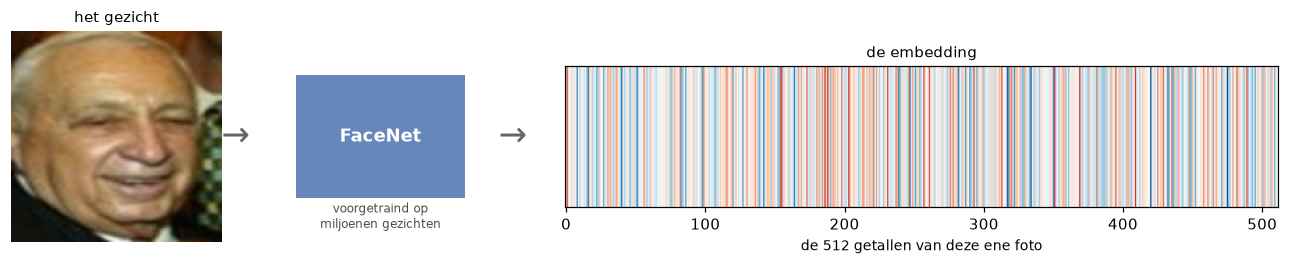

De eerste acht getallen: [ 0.064  0.085  0.003  0.007 -0.026  0.017 -0.018  0.006]
De hele vector heeft lengte 1.00.

Rood is positief, blauw is negatief. Wat die getallen afzonderlijk betekenen,
weet niemand - ook de makers van FaceNet niet. En dat hoeft ook niet:
het enige wat telt is dat twee foto's van dezelfde persoon een SOORTGELIJK
patroon krijgen, en twee verschillende mensen een ander patroon.


In [9]:
k = 0
fig = plt.figure(figsize=(12, 3.2))

# --- links: de foto die erin gaat ---
a1 = fig.add_axes([0.02, 0.15, 0.16, 0.7])
a1.imshow(gezichten[k]); a1.axis("off")
a1.set_title("het gezicht", fontsize=10)

# --- midden: het netwerk als doos ---
a2 = fig.add_axes([0.22, 0.15, 0.16, 0.7])
a2.add_patch(plt.Rectangle((0.1, 0.25), 0.8, 0.5, facecolor="#4C72B0", alpha=0.85))
a2.text(0.5, 0.5, "FaceNet", ha="center", va="center", color="white",
        fontsize=12, fontweight="bold")
a2.text(0.5, 0.13, "voorgetraind op\nmiljoenen gezichten", ha="center", fontsize=8, color="0.3")
a2.set_xlim(0, 1); a2.set_ylim(0, 1); a2.axis("off")

# --- rechts: de 512 getallen ---
a3 = fig.add_axes([0.44, 0.3, 0.54, 0.4])
a3.imshow(embeddings[k].reshape(1, -1), aspect="auto", cmap="RdBu_r", vmin=-0.15, vmax=0.15)
a3.set_yticks([]); a3.set_xlabel("de 512 getallen van deze ene foto", fontsize=9)
a3.set_title("de embedding", fontsize=10)

for x in (0.19, 0.40):
    fig.text(x, 0.5, "→", fontsize=22, ha="center", va="center", color="0.4")

plt.show()

print(f"De eerste acht getallen: {embeddings[k][:8].round(3)}")
print(f"De hele vector heeft lengte {np.linalg.norm(embeddings[k]):.2f}.")
print()
print("Rood is positief, blauw is negatief. Wat die getallen afzonderlijk betekenen,")
print("weet niemand - ook de makers van FaceNet niet. En dat hoeft ook niet:")
print("het enige wat telt is dat twee foto's van dezelfde persoon een SOORTGELIJK")
print("patroon krijgen, en twee verschillende mensen een ander patroon.")

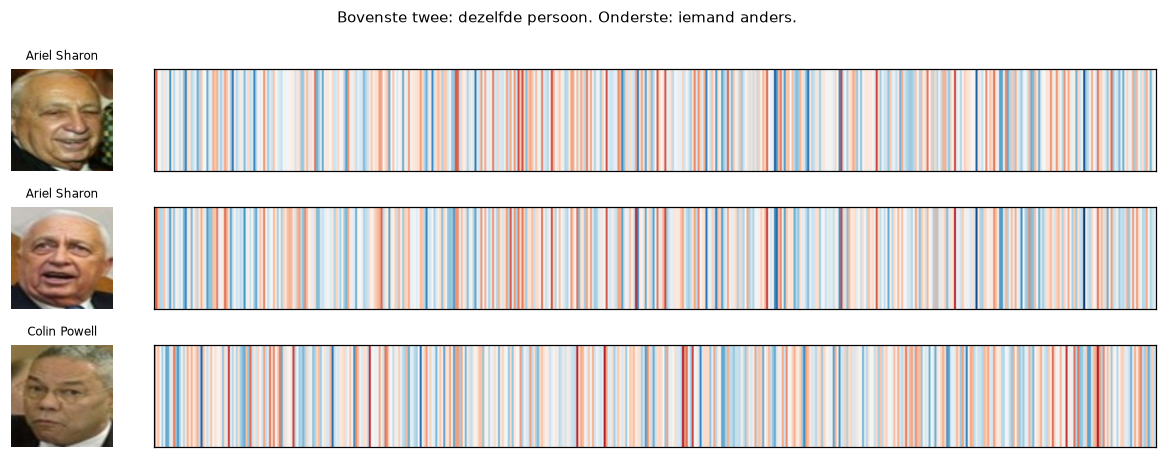

Kijk naar de strepen: de bovenste twee lijken op elkaar, de onderste wijkt af.
Meer is een embedding niet - en precies daarom kun je er verderop mee rekenen.


In [10]:
# Datzelfde patroon, voor drie foto's naast elkaar: twee keer dezelfde persoon,
# en iemand anders.
persoon = labels[0]
zelfde = np.where(labels == persoon)[0][:2]
ander  = np.where(labels != persoon)[0][0]
drie   = [zelfde[0], zelfde[1], ander]

fig, assen = plt.subplots(3, 2, figsize=(11, 4.2),
                          gridspec_kw={"width_ratios": [1, 6]})
for rij, k in enumerate(drie):
    assen[rij, 0].imshow(gezichten[k]); assen[rij, 0].axis("off")
    assen[rij, 0].set_title(labels[k], fontsize=8)
    assen[rij, 1].imshow(embeddings[k].reshape(1, -1), aspect="auto",
                         cmap="RdBu_r", vmin=-0.15, vmax=0.15)
    assen[rij, 1].set_yticks([]); assen[rij, 1].set_xticks([])
fig.suptitle("Bovenste twee: dezelfde persoon. Onderste: iemand anders.", fontsize=10)
plt.tight_layout()
plt.show()

print("Kijk naar de strepen: de bovenste twee lijken op elkaar, de onderste wijkt af.")
print("Meer is een embedding niet - en precies daarom kun je er verderop mee rekenen.")

---

## 4. Waarom werkt dat? Contrastive learning

We hebben nu 512 getallen per gezicht en de belofte dat dezelfde persoon dicht bij elkaar
ligt. Maar waaróm zou dat zo zijn? Die eigenschap komt niet uit de lucht vallen — hij is er
tijdens de training van FaceNet expres ingestopt. Wij trainen hier niets, we kijken alleen
hoe het gegaan is.

Een gewone classifier leert: *"deze foto hoort bij klasse 7."* Daar heb je een vaste lijst
klassen voor nodig, en het model kan nooit iets zeggen over iemand die niet op die lijst
staat. Voor gezichten is dat fataal: er komen altijd nieuwe mensen bij.

**Contrastive learning stelt een andere vraag:**

> *"Deze twee horen bij elkaar. Die derde niet. Zorg dat je ruimte dat weerspiegelt."*

Je hebt er geen namen voor nodig, alleen het besef welke dingen bij elkaar horen. Het model
leert geen klassen maar een **meetkunde**: een ordening waarin afstand betekenis heeft. En die
ordening werkt ook voor gezichten die het nooit gezien heeft, want ze is niet aan een lijst
namen gebonden.

### Triplet loss

De vorm die FaceNet gebruikt werkt met **drie** foto's tegelijk:

| | | |
|---|---|---|
| **anker** | een foto van persoon A | het vertrekpunt |
| **positief** | een *andere* foto van persoon A | moet dichterbij komen |
| **negatief** | een foto van persoon B | moet verder weg |

Het model wordt beloond als de afstand tot het positieve voorbeeld **kleiner** is dan de
afstand tot het negatieve, met een veiligheidsmarge ertussen. Zit het al goed, dan is er niets
te leren en is het verlies nul.

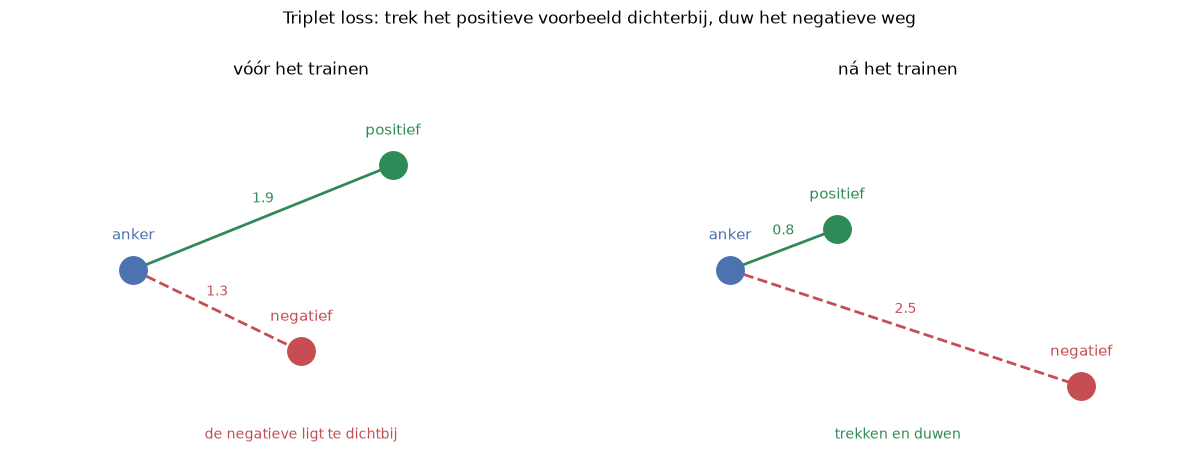

In [11]:
# De tekening die erbij hoort: voor en na.
fig, (voor, na) = plt.subplots(1, 2, figsize=(11, 4.2))

posities = {
    "voor": {"anker": (0, 0), "positief": (1.7, 0.9), "negatief": (1.1, -0.7)},
    "na":   {"anker": (0, 0), "positief": (0.7, 0.35), "negatief": (2.3, -1.0)},
}

for ax, sleutel, titel in [(voor, "voor", "vóór het trainen"), (na, "na", "ná het trainen")]:
    p = posities[sleutel]
    for naam_punt, kleur in [("anker", "#4C72B0"), ("positief", "#2E8B57"), ("negatief", "#C44E52")]:
        ax.scatter(*p[naam_punt], s=320, color=kleur, zorder=3)
        ax.annotate(naam_punt, p[naam_punt], textcoords="offset points",
                    xytext=(0, 20), ha="center", fontsize=10, color=kleur)

    for doel, kleur, stijl in [("positief", "#2E8B57", "-"), ("negatief", "#C44E52", "--")]:
        ax.plot([p["anker"][0], p[doel][0]], [p["anker"][1], p[doel][1]],
                stijl, color=kleur, lw=1.8, zorder=1)
        afstand = np.hypot(p[doel][0] - p["anker"][0], p[doel][1] - p["anker"][1])
        ax.text((p["anker"][0] + p[doel][0]) / 2, (p["anker"][1] + p[doel][1]) / 2 + 0.13,
                f"{afstand:.1f}", color=kleur, fontsize=9, ha="center")

    ax.set_xlim(-0.8, 3.0); ax.set_ylim(-1.6, 1.6)
    ax.set_title(titel, fontsize=11); ax.axis("off")

voor.text(1.1, -1.45, "de negatieve ligt te dichtbij", fontsize=9, color="#C44E52", ha="center")
na.text(1.1, -1.45, "trekken en duwen", fontsize=9, color="#2E8B57", ha="center")
fig.suptitle("Triplet loss: trek het positieve voorbeeld dichterbij, duw het negatieve weg",
             fontsize=11, y=1.0)
plt.tight_layout()
plt.show()

### Is dat dan een siamees netwerk?

Ja — maar dat woord belooft meer dan het is. Een siamees netwerk is **geen apart soort
netwerk**. Het is één heel gewoon netwerk, dat je tijdens het trainen gewoon meerdere keren
achter elkaar gebruikt, op de drie foto's van je triplet.

Er is dus ook maar **één set gewichten**. De "drie takken" die je in tekeningen ziet, zijn
driemaal dezelfde doos. In Keras is dat letterlijk:

```python
basis = maak_netwerk()        # één model

uit_a = basis(anker)          # dezelfde gewichten
uit_p = basis(positief)       # dezelfde gewichten
uit_n = basis(negatief)       # dezelfde gewichten
```

Dat het hetzelfde object is, ís de hele truc. Zou je drie losse netwerken nemen, dan zouden
hun uitvoeren in verschillende ruimtes liggen en zou afstand tussen die uitvoeren nergens op
slaan.

Waar zit het verschil met gewone training dan wél? **In de verliesfunctie.** Normaal is dat
`verlies(uitvoer, label)`: één uitvoer, één juist antwoord. Hier is het
`verlies(uitvoer_a, uitvoer_p, uitvoer_n)`: drie uitvoeren en geen juist antwoord, alleen de
eis dat ze onderling goed liggen.

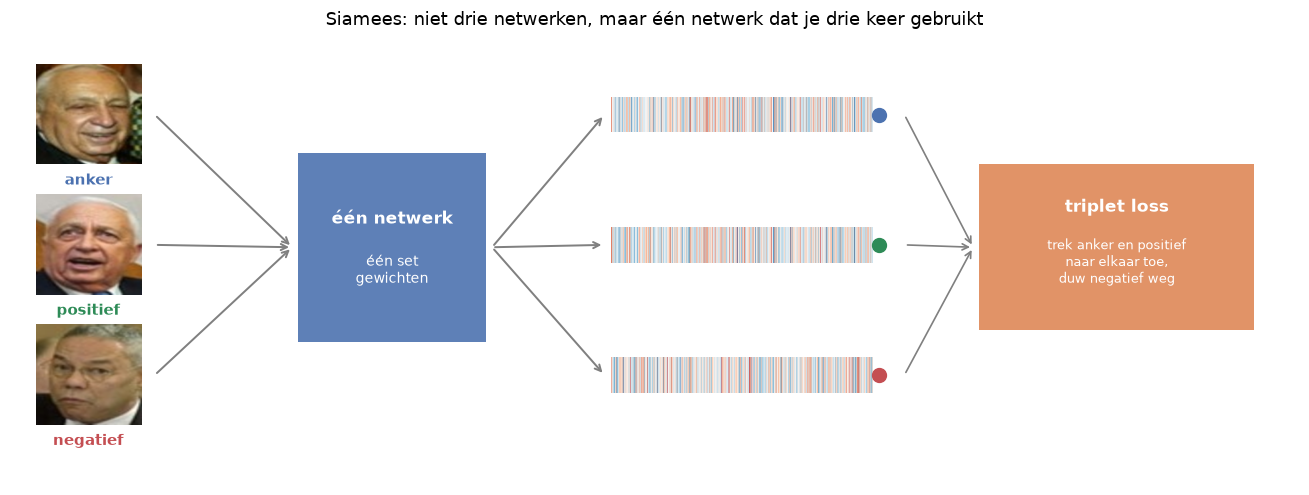

In [12]:
# Eén netwerk, drie keer gebruikt. Zo zag de training van FaceNet eruit.
fig, ax = plt.subplots(figsize=(12, 4.6))

rijen = [("anker",    zelfde[0], 2.35, "#4C72B0"),
         ("positief", zelfde[1], 1.25, "#2E8B57"),
         ("negatief", ander,     0.15, "#C44E52")]

for naam, k, y, kleur in rijen:
    ax.imshow(gezichten[k], extent=(0.0, 0.85, y, y + 0.85), aspect="auto", zorder=2)
    ax.text(0.42, y - 0.17, naam, ha="center", fontsize=9.5, fontweight="bold", color=kleur)
    # pijl naar de ENE doos in het midden
    ax.annotate("", xy=(2.05, 1.65), xytext=(0.95, y + 0.42),
                arrowprops=dict(arrowstyle="->", color="0.5", lw=1.3))

# de ene doos
ax.add_patch(plt.Rectangle((2.1, 0.85), 1.5, 1.6, facecolor="#4C72B0", alpha=0.9, zorder=3))
ax.text(2.85, 1.85, "één netwerk", ha="center", color="white", fontsize=11,
        fontweight="bold", zorder=4)
ax.text(2.85, 1.35, "één set\ngewichten", ha="center", color="white", fontsize=9, zorder=4)

# eruit: drie vectoren
for naam, k, y, kleur in rijen:
    ax.annotate("", xy=(4.55, y + 0.42), xytext=(3.65, 1.65),
                arrowprops=dict(arrowstyle="->", color="0.5", lw=1.3))
    ax.imshow(embeddings[k].reshape(1, -1), extent=(4.6, 6.7, y + 0.27, y + 0.57),
              aspect="auto", cmap="RdBu_r", vmin=-0.15, vmax=0.15, zorder=2)
    ax.plot([6.75], [y + 0.42], "o", ms=9, color=kleur, zorder=3)

# en dan het verlies
for naam, k, y, kleur in rijen:
    ax.annotate("", xy=(7.5, 1.65), xytext=(6.95, y + 0.42),
                arrowprops=dict(arrowstyle="->", color="0.5", lw=1.1))

ax.add_patch(plt.Rectangle((7.55, 0.95), 2.2, 1.4, facecolor="#DD8452", alpha=0.88))
ax.text(8.65, 1.95, "triplet loss", ha="center", color="white", fontsize=11, fontweight="bold")
ax.text(8.65, 1.35, "trek anker en positief\nnaar elkaar toe,\nduw negatief weg",
        ha="center", color="white", fontsize=8.5)

ax.set_xlim(-0.2, 10.1); ax.set_ylim(-0.35, 3.45); ax.axis("off")
ax.set_aspect("auto")
ax.set_title("Siamees: niet drie netwerken, maar één netwerk dat je drie keer gebruikt",
             fontsize=12)
plt.tight_layout()
plt.show()

En zodra de training klaar is, gooi je die hele opstelling weg. Wat je overhoudt is **één
netwerk dat één foto binnenkrijgt en één vector teruggeeft** — precies wat wij in §3 gebruikt
hebben. Van de triplets is dan niets meer te zien.

### Wat dat verlies concreet is

We trainen niets, maar we kunnen wel één keer uitrekenen wat FaceNet tijdens zijn training
miljoenen keren uitgerekend heeft. Neem een echte triplet uit onze eigen foto's.

In [13]:
a = embeddings[zelfde[0]]     # anker
p = embeddings[zelfde[1]]     # positief: dezelfde persoon
n = embeddings[ander]         # negatief: iemand anders

afstand_positief = np.sum((a - p) ** 2)
afstand_negatief = np.sum((a - n) ** 2)
marge = 0.3

verlies = max(afstand_positief - afstand_negatief + marge, 0.0)

print(f"anker    : {labels[zelfde[0]]}")
print(f"positief : {labels[zelfde[1]]}")
print(f"negatief : {labels[ander]}")
print()
print(f"afstand anker <-> positief : {afstand_positief:.3f}")
print(f"afstand anker <-> negatief : {afstand_negatief:.3f}")
print()
print("Het verlies is: (afstand tot positief) - (afstand tot negatief) + marge,")
print("en alles onder nul wordt nul.")
print(f"  max({afstand_positief:.3f} - {afstand_negatief:.3f} + {marge}, 0) = {verlies:.3f}")
print()
if verlies == 0:
    print("Nul. Deze triplet zit al goed: het positieve voorbeeld ligt ruim dichterbij")
    print("dan het negatieve. Er valt niets te leren, dus FaceNet zou hier geen")
    print("gewicht van aanpassen. Dat is precies wat je wil zien bij een model dat")
    print("klaar is met trainen.")

anker    : Ariel Sharon
positief : Ariel Sharon
negatief : Colin Powell

afstand anker <-> positief : 0.341
afstand anker <-> negatief : 1.772

Het verlies is: (afstand tot positief) - (afstand tot negatief) + marge,
en alles onder nul wordt nul.
  max(0.341 - 1.772 + 0.3, 0) = 0.000

Nul. Deze triplet zit al goed: het positieve voorbeeld ligt ruim dichterbij
dan het negatieve. Er valt niets te leren, dus FaceNet zou hier geen
gewicht van aanpassen. Dat is precies wat je wil zien bij een model dat
klaar is met trainen.


Die nul is leerzaam. Als je willekeurige triplets trekt, zit verreweg het grootste deel al
goed en is het verlies nul — dan leert het model niets en staat de training stil. FaceNet
zoekt daarom tijdens het trainen gericht naar **moeilijke negatieven**: foto's van een ánder
die toch verdacht dichtbij liggen. Dat is waar het echte werk zit, en waarom zo'n training
zoveel data nodig heeft.

### Had het ook met een gewone classifier gekund?

Dat is geprobeerd, en het werkt half. Je traint een netwerk om duizenden bekende personen te
classificeren, en gebruikt daarna de **voorlaatste laag** als embedding. De oudere
DeepFace-aanpak deed precies dat.

Twee problemen. Ten eerste moet je uitvoerlaag even breed zijn als je aantal personen — bij
een miljoen identiteiten is dat onwerkbaar. Ten tweede, en belangrijker: zo'n netwerk wordt
alleen afgerekend op het **uit elkaar houden van de klassen die het kent**. Dat die ruimte
daarbuiten ook nog netjes geordend is, is meegenomen maar wordt nergens afgedwongen.

Contrastive learning rekent het model wél direct af op wat we uiteindelijk willen weten:
liggen twee foto's van dezelfde persoon dichter bij elkaar dan twee foto's van verschillende
personen? Daardoor werkt het ook op mensen die nooit in de training zaten — en dat is wat we
in §6 gaan uitbuiten.

---

## 5. De embeddingruimte verkennen

De belofte was: dezelfde persoon ligt dicht bij elkaar. Laten we dat nagaan in plaats van
aannemen.

Als afstand gebruiken we de **cosinusafstand**: `1 - (a · b)`. Omdat alle vectoren lengte 1
hebben, loopt die netjes van 0 (identiek) tot 2 (tegenovergesteld).

In [14]:
# Alle paren in één matrixvermenigvuldiging.
afstanden = 1 - embeddings @ embeddings.T

boven = np.triu_indices(len(embeddings), k=1)     # elk paar één keer
paar_afstand = afstanden[boven]
zelfde_persoon = (labels[boven[0]] == labels[boven[1]])

print(f"aantal paren              : {len(paar_afstand):,}")
print(f"  zelfde persoon          : {zelfde_persoon.sum():,}")
print(f"  verschillende personen  : {(~zelfde_persoon).sum():,}")
print()
print(f"gemiddelde afstand, zelfde persoon        : {paar_afstand[zelfde_persoon].mean():.3f}")
print(f"gemiddelde afstand, verschillende personen: {paar_afstand[~zelfde_persoon].mean():.3f}")

aantal paren              : 204,480
  zelfde persoon          : 12,480
  verschillende personen  : 192,000

gemiddelde afstand, zelfde persoon        : 0.233
gemiddelde afstand, verschillende personen: 0.913


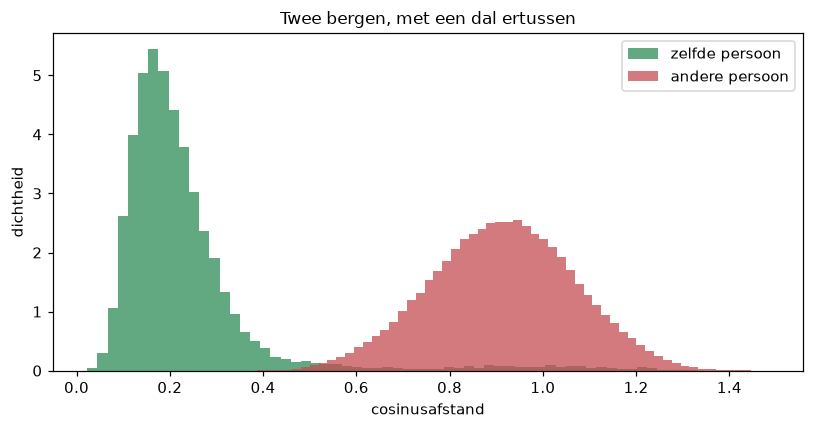

Merk op: we hebben nog NIETS getraind. Dit is puur wat FaceNet meebrengt.
En dat dal tussen de twee bergen is precies wat triplet loss erin gezet heeft.


In [15]:
fig, ax = plt.subplots(figsize=(7.5, 4))

ax.hist(paar_afstand[zelfde_persoon], bins=60, alpha=0.75, density=True,
        color="#2E8B57", label="zelfde persoon")
ax.hist(paar_afstand[~zelfde_persoon], bins=60, alpha=0.75, density=True,
        color="#C44E52", label="andere persoon")
ax.set_xlabel("cosinusafstand"); ax.set_ylabel("dichtheid")
ax.set_title("Twee bergen, met een dal ertussen", fontsize=11)
ax.legend()
plt.tight_layout()
plt.show()

print("Merk op: we hebben nog NIETS getraind. Dit is puur wat FaceNet meebrengt.")
print("En dat dal tussen de twee bergen is precies wat triplet loss erin gezet heeft.")

### Hetzelfde, maar dan om naar te kijken

512 dimensies kun je niet tekenen. Met PCA duwen we ze plat naar twee, en dan zie je waar het
in de praktijk op neerkomt: **foto's van dezelfde persoon klonteren samen.**

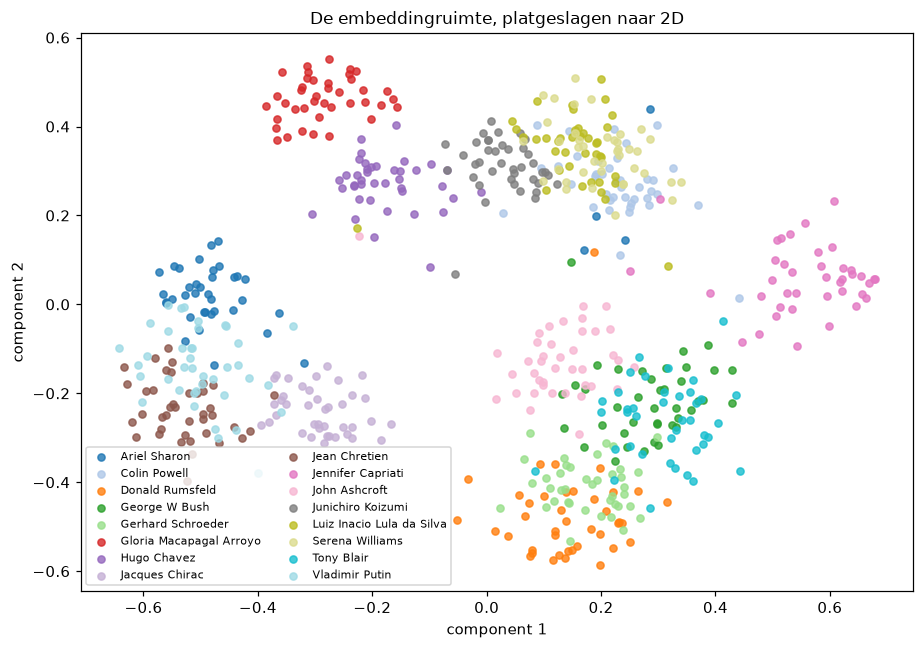

Wat je hier ziet is maar een schaduw: twee van de 512 richtingen.
Dat de groepjes dan nog steeds zichtbaar zijn, zegt hoe sterk het signaal is.


In [16]:
plat = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(embeddings)

fig, ax = plt.subplots(figsize=(8.5, 6))
kleuren = plt.cm.tab20(np.linspace(0, 1, len(personen)))
for kleur, persoon in zip(kleuren, personen):
    m = labels == persoon
    ax.scatter(plat[m, 0], plat[m, 1], s=22, color=kleur, label=persoon, alpha=0.8)
ax.set_title("De embeddingruimte, platgeslagen naar 2D", fontsize=11)
ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
ax.legend(fontsize=7, ncol=2, loc="best")
plt.tight_layout()
plt.show()

print("Wat je hier ziet is maar een schaduw: twee van de 512 richtingen.")
print("Dat de groepjes dan nog steeds zichtbaar zijn, zegt hoe sterk het signaal is.")

---

## 6. Zonder iets te trainen: een drempel op de afstand

De twee bergen uit de vorige grafiek overlappen nauwelijks. Dan is de simpelste verificatie
denkbaar al mogelijk: **leg er een grens tussen.** Ligt de afstand eronder, dan noemen we het
dezelfde persoon; ligt hij erboven, dan niet.

Dit is onze nullijn. Alles wat we hierna zelf trainen, moet hier langs — anders is het de
moeite niet waard.

### Eerst een eerlijke testopstelling

Twee vragen die je los van elkaar wil kunnen beantwoorden:

1. Werkt het voor **mensen die we gezien hebben**? (een bedrijf dat zijn eigen medewerkers herkent)
2. Werkt het voor **volslagen onbekenden**? (een systeem dat op iedereen moet werken)

Daarom splitsen we twee keer: per persoon 70/30 in foto's, én we zetten vier personen
helemaal apart. Die vier komen in geen enkele trainingsstap voor.

In [17]:
# Splitsing 1: per persoon 70% om mee te werken, 30% om op te testen.
is_train = np.zeros(len(labels), dtype=bool)
for persoon_naam in personen:
    rijen = np.where(labels == persoon_naam)[0]
    is_train[rng.choice(rijen, int(0.7 * len(rijen)), replace=False)] = True

# Splitsing 2: vier personen die we volledig buiten houden.
apart = np.random.default_rng(7)
geschud = personen.copy(); apart.shuffle(geschud)
ONGEZIEN = sorted(geschud[:4])
BEKEND   = sorted(geschud[4:])
is_ongezien = np.isin(labels, ONGEZIEN)

train_paar  = is_train & ~is_ongezien      # hier mogen we uit putten
test_bekend = ~is_train & ~is_ongezien     # bekende personen, ongeziene foto's

print("bekend (werken + testen):")
print("  " + ", ".join(BEKEND))
print("\nongezien (alleen testen):")
print("  " + ", ".join(ONGEZIEN))
print(f"\nfoto's om mee te werken     : {train_paar.sum()}")
print(f"testfoto's bekende personen : {test_bekend.sum()}")
print(f"foto's ongeziene personen   : {is_ongezien.sum()}")

bekend (werken + testen):
  Ariel Sharon, Colin Powell, Donald Rumsfeld, Gerhard Schroeder, Gloria Macapagal Arroyo, Jacques Chirac, Jennifer Capriati, Junichiro Koizumi, Luiz Inacio Lula da Silva, Serena Williams, Tony Blair, Vladimir Putin

ongezien (alleen testen):
  George W Bush, Hugo Chavez, Jean Chretien, John Ashcroft

foto's om mee te werken     : 336
testfoto's bekende personen : 144
foto's ongeziene personen   : 160


Verificatie gaat over **paren**, niet over losse foto's. Eén functie die uit een groep foto's
alle paren maakt en vraagt hoe goed een score "zelfde persoon" van "andere persoon"
onderscheidt. Die functie gebruiken we straks ook voor ons eigen model, zodat de vergelijking
eerlijk blijft.

Als maat nemen we de **AUC**: de kans dat een willekeurig gelijk paar een betere score krijgt
dan een willekeurig ongelijk paar. 1,0 is perfect, 0,5 is muntje opgooien.

**En nee, daar heb je geen kansen voor nodig.** AUC wordt meestal getoond bij een classifier
die netjes iets tussen 0 en 1 uitspuugt, en daardoor denk je al snel dat dat een eis is. Dat
is het niet. Wat binair moet zijn is het *juiste antwoord* — zelfde persoon: ja of nee. De
score mag elk getal zijn, want de ROC-curve schuift gewoon een drempel over alle waarden die
voorkomen en kijkt alleen naar de **volgorde**.

Daarom kunnen we hier de kale cosinus invoeren, die van -1 tot 1 loopt. Zet er een sigmoid
overheen en je krijgt exact dezelfde AUC: elke bewerking die de volgorde intact laat,
verandert niets.

Eén ding moet wel kloppen: **hoger moet "waarschijnlijker dezelfde persoon" betekenen.**
Daarom voeren we de similariteit in en niet de afstand. Met afstand zou je `-afstand` moeten
nemen, anders meet je 1 - AUC.

Dat is meteen waarom we in §7 de cosinus (-1 tot 1) en ons eigen netwerk (0 tot 1) in dezelfde
tabel mogen zetten: AUC kijkt niet naar de schaal, alleen naar de rangschikking.

In [18]:
def verificatie_auc(scorefunctie, masker):
    # scorefunctie(a, b) -> hoe hoger, hoe waarschijnlijker dezelfde persoon
    E, L = embeddings[masker], labels[masker]
    boven = np.triu_indices(len(E), k=1)          # elk paar één keer
    zelfde_paar = (L[boven[0]] == L[boven[1]]).astype(int)
    return roc_auc_score(zelfde_paar, scorefunctie(E[boven[0]], E[boven[1]]))


# De score zonder enige training: de cosinus tussen twee FaceNet-vectoren.
# (hoge cosinus = kleine afstand = waarschijnlijk dezelfde persoon)
cosinus = lambda a, b: np.sum(a * b, axis=1)

auc_cos_bekend   = verificatie_auc(cosinus, test_bekend)
auc_cos_ongezien = verificatie_auc(cosinus, is_ongezien)

print("FaceNet + cosinus, niets getraind:")
print(f"  bekende personen  : AUC {auc_cos_bekend:.4f}")
print(f"  ongeziene personen: AUC {auc_cos_ongezien:.4f}")
print()
print("Let op het tweede getal. Die vier personen hebben wij nergens voor")
print("gebruikt, en toch werkt het even goed. Dat is wat contrastive learning")
print("oplevert: geen lijst namen, maar een ruimte waarin afstand ook klopt")
print("voor gezichten die buiten die lijst vallen.")

FaceNet + cosinus, niets getraind:
  bekende personen  : AUC 0.9722
  ongeziene personen: AUC 0.9785

Let op het tweede getal. Die vier personen hebben wij nergens voor
gebruikt, en toch werkt het even goed. Dat is wat contrastive learning
oplevert: geen lijst namen, maar een ruimte waarin afstand ook klopt
voor gezichten die buiten die lijst vallen.


AUC is een samenvatting over alle mogelijke drempels. Maar een werkend systeem moet er één
kiezen. Dat doen we op de trainfoto's — nooit op de testfoto's, want dan meet je jezelf rijk.

In [19]:
# Alle trainparen en hun afstand.
E, L = embeddings[train_paar], labels[train_paar]
boven = np.triu_indices(len(E), k=1)
afstand_train = 1 - np.sum(E[boven[0]] * E[boven[1]], axis=1)
zelfde_train  = L[boven[0]] == L[boven[1]]

# Welke drempel doet het het best? We wegen beide fouten even zwaar, want er zijn
# veel meer ongelijke paren dan gelijke.
kandidaten = np.linspace(0.1, 1.2, 221)
balans = [((afstand_train[zelfde_train] < d).mean() +
           (afstand_train[~zelfde_train] >= d).mean()) / 2 for d in kandidaten]
DREMPEL = kandidaten[int(np.argmax(balans))]

print(f"gekozen drempel: {DREMPEL:.3f}")
print(f"  dichterbij dan {DREMPEL:.3f}  ->  zelfde persoon")
print(f"  verder weg              ->  andere persoon")


def drempel_score(masker, drempel=DREMPEL):
    E, L = embeddings[masker], labels[masker]
    b = np.triu_indices(len(E), k=1)
    afst = 1 - np.sum(E[b[0]] * E[b[1]], axis=1)
    zelfde_paar = L[b[0]] == L[b[1]]
    goed_gelijk  = (afst[zelfde_paar] < drempel).mean()
    goed_ongelijk = (afst[~zelfde_paar] >= drempel).mean()
    return goed_gelijk, goed_ongelijk


for naam_groep, masker in [("bekende personen", test_bekend), ("ongeziene personen", is_ongezien)]:
    g, o = drempel_score(masker)
    print(f"\n{naam_groep}:")
    print(f"  zelfde persoon correct herkend  : {g:.1%}")
    print(f"  andere persoon correct afgewezen: {o:.1%}")

gekozen drempel: 0.530
  dichterbij dan 0.530  ->  zelfde persoon
  verder weg              ->  andere persoon

bekende personen:
  zelfde persoon correct herkend  : 92.4%
  andere persoon correct afgewezen: 99.8%

ongeziene personen:
  zelfde persoon correct herkend  : 95.5%
  andere persoon correct afgewezen: 99.6%


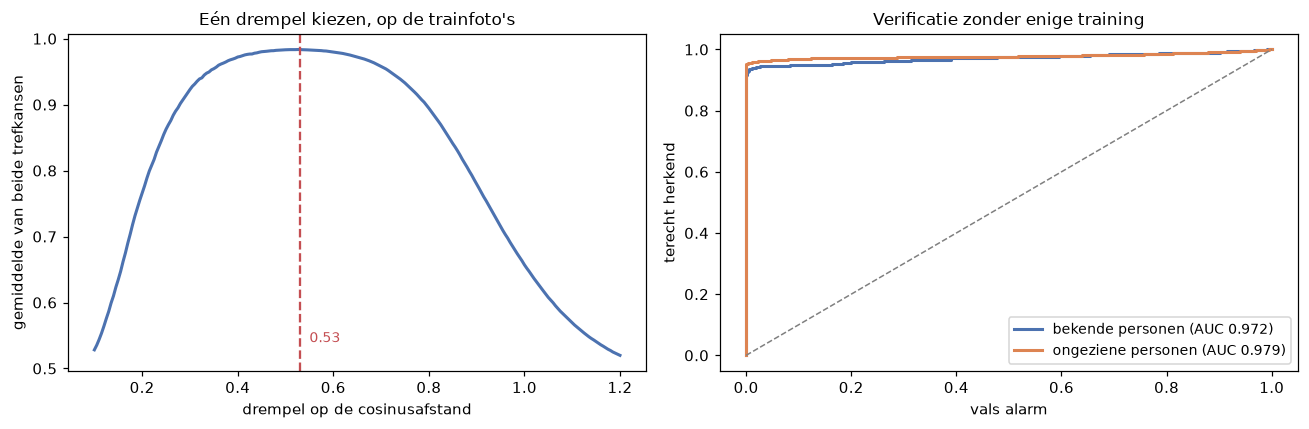

In [20]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))

a.plot(kandidaten, balans, lw=2, color="#4C72B0")
a.axvline(DREMPEL, color="#C44E52", ls="--", lw=1.5)
a.text(DREMPEL + 0.02, min(balans) + 0.02, f"{DREMPEL:.2f}", color="#C44E52", fontsize=9)
a.set_xlabel("drempel op de cosinusafstand")
a.set_ylabel("gemiddelde van beide trefkansen")
a.set_title("Eén drempel kiezen, op de trainfoto's", fontsize=11)

for masker, naam_groep, kleur in [(test_bekend, "bekende personen", "#4C72B0"),
                                  (is_ongezien, "ongeziene personen", "#DD8452")]:
    E, L = embeddings[masker], labels[masker]
    bo = np.triu_indices(len(E), k=1)
    zp = (L[bo[0]] == L[bo[1]]).astype(int)
    sc = np.sum(E[bo[0]] * E[bo[1]], axis=1)
    fpr, tpr, _ = roc_curve(zp, sc)
    b.plot(fpr, tpr, lw=2, color=kleur,
           label=f"{naam_groep} (AUC {roc_auc_score(zp, sc):.3f})")

b.plot([0, 1], [0, 1], "--", lw=1, color="grey")
b.set_xlabel("vals alarm"); b.set_ylabel("terecht herkend")
b.set_title("Verificatie zonder enige training", fontsize=11)
b.legend(fontsize=9, loc="lower right")

plt.tight_layout()
plt.show()

---

## 7. Ons eigen netwerk op het verschil

De nullijn staat. Nu zetten we er zelf iets tussen.

Tot hier hielden we de **meetlat vast**: cosinusafstand, een vaste formule die elk van de 512
getallen even zwaar weegt. Maar waarom zou dat de beste manier zijn om twee gezichten te
vergelijken? Misschien zijn sommige van die 512 richtingen veel betekenisvoller dan andere.
Misschien doet een combinatie van twee richtingen er meer toe dan elk apart.

Dat kunnen we laten uitzoeken. We trainen een klein netwerk dat **twee embeddings
binnenkrijgt** en zegt: *"zelfde persoon: ja of nee."* De embeddings van FaceNet laten we
precies zoals ze zijn — we leren alleen de vergelijking.

Dat is een erkende techniek: een **learned metric** of verificatienetwerk. De Siamese
one-shot-paper van Koch (2015) doet precies dit.

### Hoe voer je twee vectoren in één netwerk?

Niet door ze simpelweg achter elkaar te plakken. Dan leert het model dat "a links, b rechts"
iets anders is dan "b links, a rechts", terwijl dat dezelfde vraag is. We geven het netwerk
daarom twee combinaties die **symmetrisch** zijn:

| | | waarom |
|---|---|---|
| `\|a - b\|` | het verschil per getal | waar wijken de twee gezichten af? |
| `a * b` | het product per getal | waar zijn ze het juist eens? |

Samen 1024 getallen, en of je nu `(a, b)` of `(b, a)` invoert maakt niets uit.

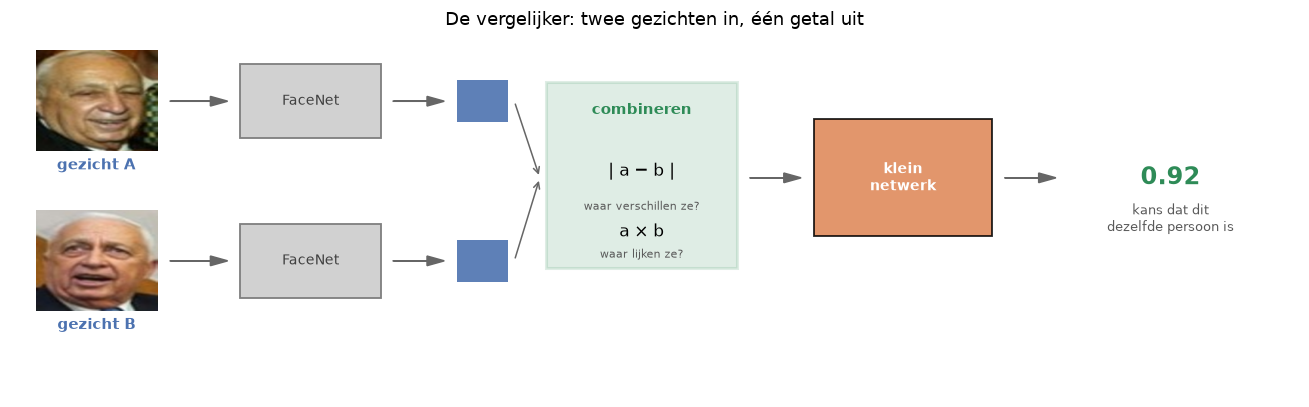

In [21]:
# Ook deze architectuur even uittekenen, naast die van hierboven.
fig, ax = plt.subplots(figsize=(12, 3.8))

for naam, y in [("gezicht A", 1.85), ("gezicht B", 0.35)]:
    k = zelfde[0] if naam.endswith("A") else zelfde[1]   # twee foto's van dezelfde persoon
    ax.imshow(gezichten[k], extent=(0.0, 0.95, y, y + 0.95), aspect="auto")
    ax.text(0.47, y - 0.17, naam, ha="center", fontsize=10, fontweight="bold", color="#4C72B0")
    ax.arrow(1.05, y + 0.47, 0.45, 0, head_width=0.09, color="0.4", length_includes_head=True)
    ax.add_patch(plt.Rectangle((1.6, y + 0.12), 1.1, 0.7, facecolor="0.82",
                               edgecolor="0.5", lw=1.2))
    ax.text(2.15, y + 0.47, "FaceNet", ha="center", va="center", fontsize=9, color="0.25")
    ax.arrow(2.8, y + 0.47, 0.4, 0, head_width=0.09, color="0.4", length_includes_head=True)
    ax.add_patch(plt.Rectangle((3.3, y + 0.27), 0.4, 0.4, facecolor="#4C72B0", alpha=0.9))

# combineren
ax.add_patch(plt.Rectangle((4.0, 0.75), 1.5, 1.75, facecolor="#2E8B57", alpha=0.15,
                           edgecolor="#2E8B57", lw=2))
ax.text(4.75, 2.2, "combineren", ha="center", fontsize=10, fontweight="bold", color="#2E8B57")
ax.text(4.75, 1.62, "| a − b |", ha="center", fontsize=11)
ax.text(4.75, 1.3, "waar verschillen ze?", ha="center", fontsize=7.5, color="0.35")
ax.text(4.75, 1.05, "a × b", ha="center", fontsize=11)
ax.text(4.75, 0.85, "waar lijken ze?", ha="center", fontsize=7.5, color="0.35")
for y in (2.32, 0.82):
    ax.annotate("", xy=(3.95, 1.6), xytext=(3.75, y),
                arrowprops=dict(arrowstyle="->", color="0.4"))

ax.arrow(5.6, 1.6, 0.4, 0, head_width=0.09, color="0.4", length_includes_head=True)
ax.add_patch(plt.Rectangle((6.1, 1.05), 1.4, 1.1, facecolor="#DD8452", alpha=0.85,
                           edgecolor="black", lw=1.2))
ax.text(6.8, 1.6, "klein\nnetwerk", ha="center", va="center", fontsize=9,
        color="white", fontweight="bold")
ax.arrow(7.6, 1.6, 0.4, 0, head_width=0.09, color="0.4", length_includes_head=True)
ax.text(8.9, 1.6, "0.92", ha="center", va="center", fontsize=16, fontweight="bold",
        color="#2E8B57")
ax.text(8.9, 1.1, "kans dat dit\ndezelfde persoon is", ha="center", fontsize=8.5, color="0.35")

ax.set_xlim(-0.2, 9.9); ax.set_ylim(-0.45, 2.95); ax.axis("off")
ax.set_title("De vergelijker: twee gezichten in, één getal uit", fontsize=12)
plt.tight_layout()
plt.show()

Zie je het verschil met de vorige tekening? Daar kwamen er aan het eind **drie vectoren** uit
en berekenden we zelf de afstanden. Hier komt er één **getal** uit, en dat getal ís het
antwoord.

Dat lijkt handiger, en voor één vergelijking is het dat ook. Maar er zit een addertje onder het
gras dat je pas ziet als je gaat opschalen — dat bespreken we zo.

In [22]:
def maak_vergelijker(dim=512):
    gezicht_a = keras.Input(shape=(dim,), name="gezicht_a")
    gezicht_b = keras.Input(shape=(dim,), name="gezicht_b")

    # Twee symmetrische manieren om de vectoren te combineren.
    verschil = layers.Lambda(lambda t: ops.abs(t), name="absoluut_verschil")(
        layers.Subtract(name="verschil")([gezicht_a, gezicht_b]))
    product = layers.Multiply(name="product")([gezicht_a, gezicht_b])
    samen = layers.Concatenate(name="samen")([verschil, product])

    x = layers.Dense(128, activation="relu", name="verborgen1")(samen)
    x = layers.Dropout(0.3, name="dropout")(x)
    x = layers.Dense(64, activation="relu", name="verborgen2")(x)
    oordeel = layers.Dense(1, activation="sigmoid", name="zelfde_persoon")(x)

    return keras.Model([gezicht_a, gezicht_b], oordeel, name="vergelijker")


keras.utils.set_random_seed(RANDOM_STATE)
vergelijker = maak_vergelijker()
vergelijker.compile(optimizer=keras.optimizers.Adam(1e-3),
                    loss="binary_crossentropy", metrics=["accuracy"])
vergelijker.summary(line_length=88)

Model: "vergelijker"

┏━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)            ┃ Output Shape         ┃      Param # ┃ Connected to         ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ gezicht_a (InputLayer)  │ (None, 512)          │            0 │ -                    │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ gezicht_b (InputLayer)  │ (None, 512)          │            0 │ -                    │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ verschil (Subtract)     │ (None, 512)          │            0 │ gezicht_a[0][0],     │
│                         │                      │              │ gezicht_b[0][0]      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ absoluut_verschil       │ (None, 512)          │            0 │ verschil[0][0]       │
│ (Lambda)                │                      │              │                      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ product (Multiply)      │ (None, 512)          │            0 │ gezicht_a[0][0],     │
│                         │                      │              │ gezicht_b[0][0]      │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ samen (Concatenate)     │ (None, 1024)         │            0 │ absoluut_verschil[0… │
│                         │                      │              │ product[0][0]        │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ verborgen1 (Dense)      │ (None, 128)          │      131,200 │ samen[0][0]          │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ dropout (Dropout)       │ (None, 128)          │            0 │ verborgen1[0][0]     │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ verborgen2 (Dense)      │ (None, 64)           │        8,256 │ dropout[0][0]        │
├─────────────────────────┼──────────────────────┼──────────────┼──────────────────────┤
│ zelfde_persoon (Dense)  │ (None, 1)            │           65 │ verborgen2[0][0]     │
└─────────────────────────┴──────────────────────┴──────────────┴──────────────────────┘

 Total params: 139,521 (545.00 KB)

 Trainable params: 139,521 (545.00 KB)

 Non-trainable params: 0 (0.00 B)

40,000 paren: 20,000 zelfde persoon, 20,000 verschillende


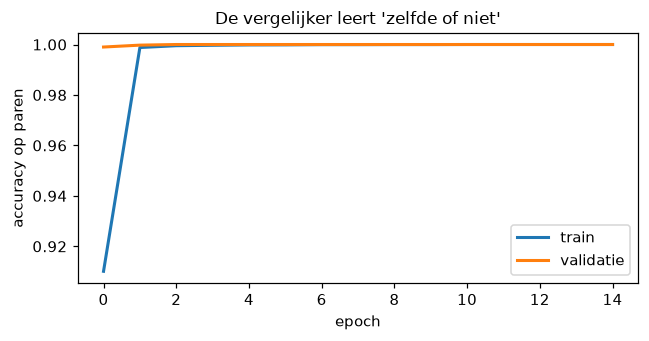

In [23]:
def maak_paren(emb, lab, aantal, rng):
    # Evenveel 'zelfde persoon' als 'andere persoon', anders leert het model
    # gewoon altijd 'nee' te zeggen: dat klopt in 95% van de willekeurige paren.
    per_persoon = {p: np.where(lab == p)[0] for p in set(lab)}
    wie = list(per_persoon)

    links, rechts, doel = [], [], []
    for _ in range(aantal // 2):
        a = rng.choice(wie)
        i, j = rng.choice(per_persoon[a], 2, replace=False)
        links.append(emb[i]); rechts.append(emb[j]); doel.append(1)

        b = rng.choice([w for w in wie if w != a])
        m, k = rng.choice(per_persoon[a]), rng.choice(per_persoon[b])
        links.append(emb[m]); rechts.append(emb[k]); doel.append(0)

    return np.array(links), np.array(rechts), np.array(doel, dtype="float32")


L_paar, R_paar, Y_paar = maak_paren(
    embeddings[train_paar], labels[train_paar], 40_000, np.random.default_rng(RANDOM_STATE))
print(f"{len(L_paar):,} paren: {int(Y_paar.sum()):,} zelfde persoon, "
      f"{int((1 - Y_paar).sum()):,} verschillende")

historie_paar = vergelijker.fit([L_paar, R_paar], Y_paar,
                                epochs=15, batch_size=256, validation_split=0.1, verbose=0)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(historie_paar.history["accuracy"], lw=2, label="train")
ax.plot(historie_paar.history["val_accuracy"], lw=2, label="validatie")
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy op paren"); ax.legend()
ax.set_title("De vergelijker leert 'zelfde of niet'", fontsize=11)
plt.tight_layout()
plt.show()

In [24]:
# De uitvoer van het netwerk is nu zelf de score.
def score_vergelijker(a, b):
    return vergelijker.predict([a, b], verbose=0, batch_size=4096).ravel()

auc_paar_bekend   = verificatie_auc(score_vergelijker, test_bekend)
auc_paar_ongezien = verificatie_auc(score_vergelijker, is_ongezien)

print(f"bekende personen  : AUC {auc_paar_bekend:.4f}   (cosinus was {auc_cos_bekend:.4f})")
print(f"ongeziene personen: AUC {auc_paar_ongezien:.4f}   (cosinus was {auc_cos_ongezien:.4f})")

bekende personen  : AUC 0.9929   (cosinus was 0.9722)
ongeziene personen: AUC 0.9901   (cosinus was 0.9785)


In [25]:
overzicht = pd.DataFrame([
    {"aanpak": "FaceNet + cosinus (niets getraind)",
     "bekende personen": auc_cos_bekend,  "ongeziene personen": auc_cos_ongezien,
     "snel doorzoekbaar": "ja"},
    {"aanpak": "onze vergelijker (getraind op paren)",
     "bekende personen": auc_paar_bekend, "ongeziene personen": auc_paar_ongezien,
     "snel doorzoekbaar": "nee"},
]).set_index("aanpak").round(4)

display(overzicht)

,bekende personen,ongeziene personen,snel doorzoekbaar
aanpak,,,
FaceNet + cosinus (niets getraind),0.9722,0.9785,ja
onze vergelijker (getraind op paren),0.9929,0.9901,nee


### De waarschuwing

Onze vergelijker wint op beide kolommen, ook bij de vier personen die hij nooit gezien heeft.
Hij heeft dus niet onze zestien mensen uit zijn hoofd geleerd — hij heeft echt een betere
manier van vergelijken geleerd, en die generaliseert.

Toch is "beter" hier niet hetzelfde als "altijd de betere keuze". Kijk naar de laatste kolom.

**Met cosinusafstand is een embedding een adres.** Je rekent elk gezicht één keer uit, slaat
die 512 getallen op, en vergelijken is daarna één vermenigvuldiging. Een miljoen gezichten in
een vectordatabase doorzoeken kost milliseconden, want zo'n database kan op afstand
indexeren — hij weet dat punten die ver van elkaar liggen niet eens bekeken hoeven te worden.

**Bij onze vergelijker bestaat die afstand niet meer.** Er is geen getal dat je vooraf kunt
uitrekenen en opslaan, want het oordeel ontstaat pas op het moment dat je twee gezichten
samen door het netwerk duwt. Eén gezicht tegen een miljoen andere houden betekent dus: een
miljoen keer het netwerk draaien. Er valt niets te indexeren en niets over te slaan.

| | cosinusafstand | onze vergelijker |
|---|---|---|
| Wat is het? | een vaste formule | een getraind netwerk |
| Nauwkeuriger | nee | ja |
| Vergelijking vooraf uitrekenen | ja, één keer per gezicht | nee, pas bij het paar zelf |
| Zoeken in een grote database | snel (vectorindex) | traag (N keer het model draaien) |
| Typisch gebruikt voor | zoeken, clusteren, aanbevelen | één-op-één verifiëren |

**De praktijkregel die hieruit volgt:** moet je zóéken in een grote verzameling — wie van onze
tienduizend klanten is dit? — dan wil je een embedding en een vaste afstandsmaat, ook al is
die iets minder nauwkeurig. Moet je twee dingen vergelijken die je toch al in handen hebt —
een selfie tegen de pasfoto op je identiteitskaart, een vingerafdruk tegen die ene opgeslagen
afdruk — dan is een vergelijker prima, en meestal beter.

Nog een tweede kanttekening, want AUC's van 0,99 zien er mooier uit dan ze zijn. LFW bestaat
uit persfoto's van publieke figuren: scherp, van voren, goed belicht. Zet dit op beelden van
een bewakingscamera en beide getallen zakken fors. Wat je hier ziet is dat de vergelijker
beter is **dan de cosinusafstand op deze data** — niet dat gezichtsverificatie een opgelost
probleem is.

---

## 8. Je eigen foto

De hele pijplijn staat er: gezicht vinden, embedding maken, vergelijken. En let op wat er
**niet** meer hoeft: we hoeven niets bij te trainen om een nieuw gezicht aan te kunnen. Je
levert twee foto's aan en je krijgt een antwoord — ook van mensen die in geen enkele
trainingsstap voorkwamen.

Zo werkt de gezichtsontgrendeling van je telefoon ook. Die kent maar één referentie, de jouwe,
en vergelijkt daar elke keer tegen.

**Je eigen foto's toevoegen:**

1. Maak in `data/mijn-gezichten/` een map met jouw naam, bijvoorbeeld `data/mijn-gezichten/Kristof/`.
2. Zet er minstens **twee** foto's van jezelf in (gewone JPEG's, gezicht duidelijk in beeld).
3. Wil je het spannender maken: voeg ook een map van een huisgenoot of collega toe.
4. Draai de cellen hieronder opnieuw.

Werkt ook zonder eigen foto's — dan gebruikt de notebook foto's uit de dataset.

In [26]:
# De twee stappen van hiervoor, nu als één functie voor een losse foto.
def embedding_van_foto(pad):
    foto = np.array(Image.open(pad).convert("RGB"))
    kandidaten = detector.detect_faces(foto)
    if not kandidaten:
        return None, None

    beste = max(kandidaten, key=lambda d: d["confidence"])
    x, y, w, h = beste["box"]
    dx, dy = int(w * 0.15), int(h * 0.15)
    x, y = max(0, x - dx), max(0, y - dy)
    uitsnede = np.array(Image.fromarray(foto[y:y + h + 2 * dy, x:x + w + 2 * dx]).resize((160, 160)))

    return uitsnede, embedder.embeddings(uitsnede[None, ...])[0]


def vergelijk(pad_a, pad_b, titel=""):
    knip_a, vec_a = embedding_van_foto(pad_a)
    knip_b, vec_b = embedding_van_foto(pad_b)
    if vec_a is None or vec_b is None:
        print(f"{titel}: op minstens een van beide foto's geen gezicht gevonden")
        return

    # Twee oordelen: de vaste meetlat uit §6 en ons eigen netwerk uit §7.
    afstand = 1 - float(vec_a @ vec_b)
    kans    = float(vergelijker.predict([vec_a[None, :], vec_b[None, :]], verbose=0)[0, 0])

    oordeel_drempel    = "ZELFDE PERSOON" if afstand < DREMPEL else "ANDERE PERSOON"
    oordeel_vergelijker = "ZELFDE PERSOON" if kans > 0.5 else "ANDERE PERSOON"

    fig, (a, b, c) = plt.subplots(1, 3, figsize=(10, 3.4),
                                  gridspec_kw={"width_ratios": [1, 1, 1.5]})
    a.imshow(knip_a); a.axis("off"); a.set_title(Path(pad_a).parent.name, fontsize=9)
    b.imshow(knip_b); b.axis("off"); b.set_title(Path(pad_b).parent.name, fontsize=9)

    kleur = "#2E8B57" if oordeel_vergelijker == "ZELFDE PERSOON" else "#C44E52"
    c.axis("off")
    c.text(0.0, 0.88, titel, fontsize=10, fontweight="bold", color="0.3")
    c.text(0.0, 0.62, f"afstand {afstand:.3f}  (drempel {DREMPEL:.2f})", fontsize=9.5)
    c.text(0.0, 0.46, f"-> {oordeel_drempel}", fontsize=9.5, color="0.35")
    c.text(0.0, 0.22, f"vergelijker: {kans:.1%}", fontsize=9.5)
    c.text(0.0, 0.06, f"-> {oordeel_vergelijker}", fontsize=11, color=kleur, fontweight="bold")
    plt.tight_layout()
    plt.show()

Eerst twee paren uit de dataset — en met opzet uit de **ongeziene** personen, zodat niets van
wat we getraind hebben deze gezichten ooit gezien heeft.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


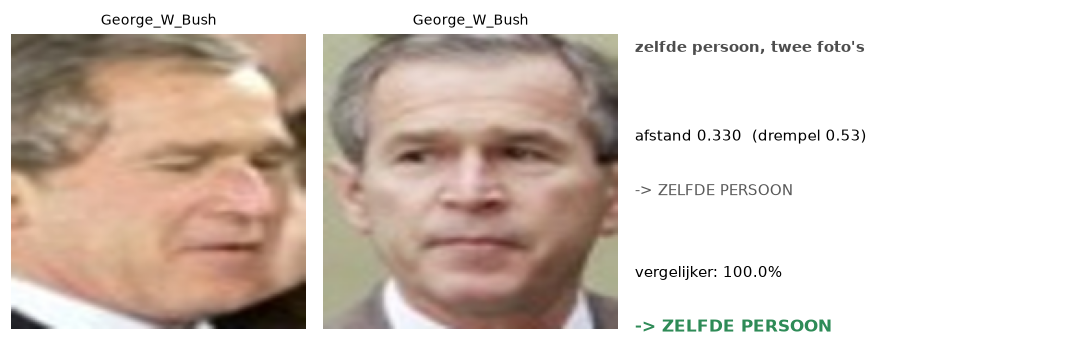

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


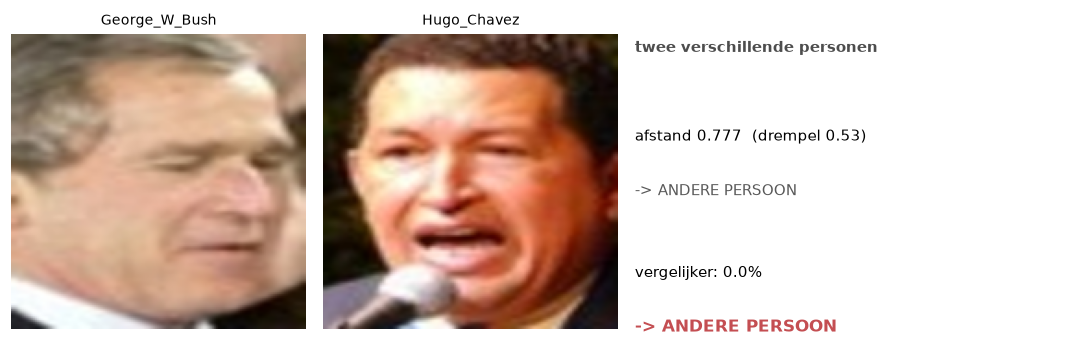

In [27]:
eerste  = np.where(labels == ONGEZIEN[0])[0][:2]      # twee foto's van dezelfde persoon
tweede  = np.where(labels == ONGEZIEN[1])[0][0]       # en iemand anders

vergelijk(paden_ok[eerste[0]], paden_ok[eerste[1]], "zelfde persoon, twee foto's")
vergelijk(paden_ok[eerste[0]], paden_ok[tweede],    "twee verschillende personen")

In [28]:
EIGEN = Path("data/mijn-gezichten")
eigen_paden = sorted([p for p in EIGEN.rglob("*")
                      if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]) if EIGEN.exists() else []

if not eigen_paden:
    print("Nog geen eigen foto's in data/mijn-gezichten/.")
    print("Zet er twee van jezelf in en draai deze cel opnieuw.")
else:
    print(f"{len(eigen_paden)} eigen foto's gevonden:")
    for p in eigen_paden:
        print(f"   {p.parent.name:20s} {p.name}")

    # Per map: twee foto's van dezelfde persoon tegen elkaar.
    per_map = {}
    for p in eigen_paden:
        per_map.setdefault(p.parent.name, []).append(p)

    for naam_map, lijst in per_map.items():
        if len(lijst) >= 2:
            vergelijk(lijst[0], lijst[1], f"{naam_map} tegen zichzelf")

    # En jouw gezicht tegen een wildvreemde uit de dataset.
    eerste_eigen = eigen_paden[0]
    vreemde = paden_ok[np.where(labels == ONGEZIEN[0])[0][0]]
    vergelijk(eerste_eigen, vreemde, "jij tegen een vreemde")

Nog geen eigen foto's in data/mijn-gezichten/.
Zet er twee van jezelf in en draai deze cel opnieuw.


Wat hier gebeurd is, is de moeite waard om even bij stil te staan: wij hebben nergens iets
met jouw gezicht getraind, en toch werkt het. Niet omdat het model jou kent, maar omdat het geleerd
heeft wat "dezelfde persoon" betekent.

Dat is het verschil tussen een model dat namen voorspelt en een model dat een ruimte leert.
En het is meteen het antwoord op de vraag waarom contrastive learning zo veel verder reikt dan
gezichten: dezelfde opzet — leren welke dingen bij elkaar horen in plaats van hoe ze heten —
zit onder beeldzoekmachines, muziekaanbevelingen en de tekstembeddings waar taalmodellen hun
documenten mee ophalen.